<a href="https://www.kaggle.com/code/matheusaccioly/when-and-where-is-new-music-coming-from?scriptVersionId=366686520" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Introduction

*Inspired by the work and data provided by user [kai](https://www.kaggle.com/kaitoland) and made as the Capstone Project for the Google Data Analysis certification course.*

**Question:** Do country-level patterns of new-artist debuts vary over time and associate with major economic and political events? What those patterns can tell us about how culture, technology and politcs shape who gets to make art, and where?

This exploratory study uses the MusicBrainz core database dump of 2026-10-24 (20261024-102842) to examine how new musical artists emerge across countries and over time. The dataset contains 5,328,728 official releases credited to 917,257 artists. Each row represents one official MusicBrainz release and records the first credited artist, release title, date of the earliest release event, release-group type, and the country of that earliest event. By sorting each artist’s releases chronologically, I reconstruct artist-level release timelines, capturing debut timing and the country in which releases first appeared. I then aggregate these timelines into country-year counts of new artists debuting between 1950 and 2025. 

Initial visualization suggests that major economic, technological and political disruptions, such as the Vietnam War, the release of the iPod, the widespread adoption of music streaming, the 2008 housing crisis, and the COVID-19 pandemic are correlated with fluctuations in the number of new artists. **In essence, people choose to pursue music careers when their material reality allows them to.**

Two countries nonetheless stand as conspicuous exceptions to the otherwise broad decline in new-artist counts: Andorra, whose outlier status plausibly reflects legislation designed to promote artists [1](https://www.govern.ad/ca/w/s-obre-la-convocatoria-de-l-ajuda-a-la-professionalitzacio-dels-artistes-musicals-per-valor-de-40-000-euros); and Japan, one of the few countries worldwide in which purchases of physical media continue to outpace the growth of streaming [2](https://interspacemusic.com/blog/japan-is-the-worlds-no-2-music-market-and-grew-8-9-in-2025-it-is-still-half-physical/).

Because the measure is based on official MusicBrainz releases and the country of earliest release event, the analysis is exploratory and correlational rather than causal.

![Imgur](https://i.imgur.com/am3wVpH.png)

[Interactive version on Tableau](https://public.tableau.com/views/DataStory-Whenandwhereisnewmusiccomingfrom/Whenandwhereisnewmusiccomingfrom?:language=pt-BR&:sid=&:redirect=auth&:display_count=n&:origin=viz_share_link)

**Caveats that apply to every number below**

- Only **official** releases are in the file (promotion, bootleg, pseudo-release and withdrawn rows were left out at build time).
- The artist is the **first credited artist** only. Featured or second artists are not counted.
- The date is the **earliest release event**. Month and day are blank when MusicBrainz does not know them.
- Classical composers (Bach, Mozart) appear as first artists because MusicBrainz credits the composer.
- A "release" is one MusicBrainz release, so a country edition or a reissue of the same title is a separate row.
- US data is probably over-represented in comparison to other regions simply due to the fact that more music is released there than anywhere else. This shouldn't impact the overall trends and analyses.

# Cleaning and preparation

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import country_converter as coco
import seaborn.objects as so
from seaborn import axes_style


def find_csv(name="official_releases.csv"):
    """Search /kaggle/input first (any mount path), then the working folder."""
    for root in (Path("/kaggle/input"), Path(".")):
        if not root.exists():
            continue
        hits = sorted(p for p in root.rglob(name) if p.is_file())
        if hits:
            return hits[0]
    raise FileNotFoundError(name)

CSV = find_csv()
print("reading", CSV)

reading /kaggle/input/artist-release-timeline/official_releases.csv


In [2]:
f_df = pd.read_csv(CSV, dtype=str, keep_default_na=False,
                 usecols=["artist_name", "date_year", "country_code"])
f_df["year"] = pd.to_numeric(f_df["date_year"], errors="coerce")
f_df.head()

,artist_name,date_year,country_code,year
0,Tori Amos,2002,DE,2002.0
1,Tori Amos,2002,GB,2002.0
2,Tori Amos,1997,DE,1997.0
3,Super Furry Animals,1998,JP,1998.0
4,Super Furry Animals,1998,GB,1998.0


**Main Filters**

- Filtering the year interval as per kai's [recommendation](https://www.kaggle.com/code/kaitoland/which-years-the-release-file-really-covers): from 1950 to 2025.
- Filtering out rows contatining invalid, empty or irrelevant ISO2 codes related to continents, worldwide releases, regional releases, etc.
- Filtering out irrelevant or broken artist names, such as "Various Artists", "[unknown]˜, "[no artist]", etc.
- Filtering out artist names comprised of only numerical values (artist names featuring both numbers and symbols are still kept).

In [3]:
f_df = f_df[f_df["year"].between(1950, 2025)]
f_df = f_df[~f_df["country_code"].isin(["XW", "XE", "", "XZ", "XC", "SU", "CS", "AN", "YU", "XG"] + [None])]
f_df = f_df[~f_df["artist_name"].isin(["Various Artists", "", "[unknown]", "[dialogue]", "[no artist]"] + [None])]
f_df = f_df[~f_df["artist_name"].str.fullmatch(r"\d+").fillna(False)]
f_df.head()

,artist_name,date_year,country_code,year
0,Tori Amos,2002,DE,2002.0
1,Tori Amos,2002,GB,2002.0
2,Tori Amos,1997,DE,1997.0
3,Super Furry Animals,1998,JP,1998.0
4,Super Furry Animals,1998,GB,1998.0


# Constructing the main table

**Step 1**

First, we find the debut year of each artist by finding their earliest release.

In [4]:
debut_year = (
    f_df.groupby("artist_name")["year"]
      .min()
      .reset_index()
      .rename(columns={"year": "debut_year"})
)
debut_year.head()

,artist_name,debut_year
0,!!!,1998.0
1,!!ii,2020.0
2,!@#$%,2017.0
3,!ASQ!,2003.0
4,!ATTENTION!,2011.0


**Step 2**

We join the debut years we found back to the main table.


In [5]:
df_debut = f_df.merge(debut_year, on="artist_name")
df_debut = df_debut[df_debut["year"] == df_debut["debut_year"]]
debut_countries = df_debut[["artist_name", "country_code"]].drop_duplicates()

df_debut.head()

,artist_name,date_year,country_code,year,debut_year
7,Mhoo,2011,NO,2011.0,2011.0
8,Café Tacvba,1992,US,1992.0,1992.0
19,Fueled,1997,US,1997.0,1997.0
31,Noé Preszow,2021,FR,2021.0,2021.0
34,Busted,2002,GB,2002.0,2002.0


**Step 3**

To build the country-level sums of artist debuts, each artist must be assigned a single debut country, since multiple earliest releases may occur in different countries within the same year. When an artist has more than one country in the debut year, the country with the most overall releases is selected; ties are broken alphabetically.

In [6]:
total_per_country = (
    df_debut.groupby(["artist_name", "country_code"])
      .size()
      .reset_index(name="total_releases")
)
total_per_country.head()

,artist_name,country_code,total_releases
0,!!!,US,2
1,!!ii,EE,1
2,!@#$%,US,1
3,!ASQ!,US,1
4,!ATTENTION!,CA,1


In [7]:
country_choice = (
    debut_countries
      .merge(total_per_country, on=["artist_name", "country_code"], how="left")
      .sort_values(
          ["artist_name", "total_releases", "country_code"],
          ascending=[True, False, True]
      )
      .drop_duplicates("artist_name", keep="first")
      .rename(columns={"country_code": "debut_country"})
      [["artist_name", "debut_country"]]
)

country_choice.head()

,artist_name,debut_country
505594,!!!,US
310936,!!ii,EE
258342,!@#$%,US
46944,!ASQ!,US
487001,!ATTENTION!,CA


In [8]:
debut_count = debut_year.merge(country_choice, on="artist_name")

debut_count = (
    debut_count
      .groupby(["debut_country", "debut_year"])
      .size()
      .reset_index(name="debuting_artists")
      .rename(columns={"debut_country": "country_code", "debut_year": "year"})
      .sort_values(["year", "country_code"])
      .reset_index(drop=True)
)

debut_count.sort_values(by="debuting_artists", ascending=False).head()

,country_code,year,debuting_artists
4027,US,2007.0,4612
3896,US,2006.0,4521
4411,US,2010.0,4443
3782,US,2005.0,4422
4151,US,2008.0,4360


Adding a country name column to the table:

In [9]:
cc = coco.CountryConverter()

debut_count["country_name"] = cc.convert(
    names=debut_count["country_code"], 
    src="ISO2", 
    to="name_short"
)

debut_count.to_csv("artist_debut_per_country_per_year.csv", index=False)
debut_count.head()


,country_code,year,debuting_artists,country_name
0,AR,1950.0,1,Argentina
1,AT,1950.0,1,Austria
2,AU,1950.0,9,Australia
3,BE,1950.0,2,Belgium
4,BR,1950.0,3,Brazil


# Early Exploration

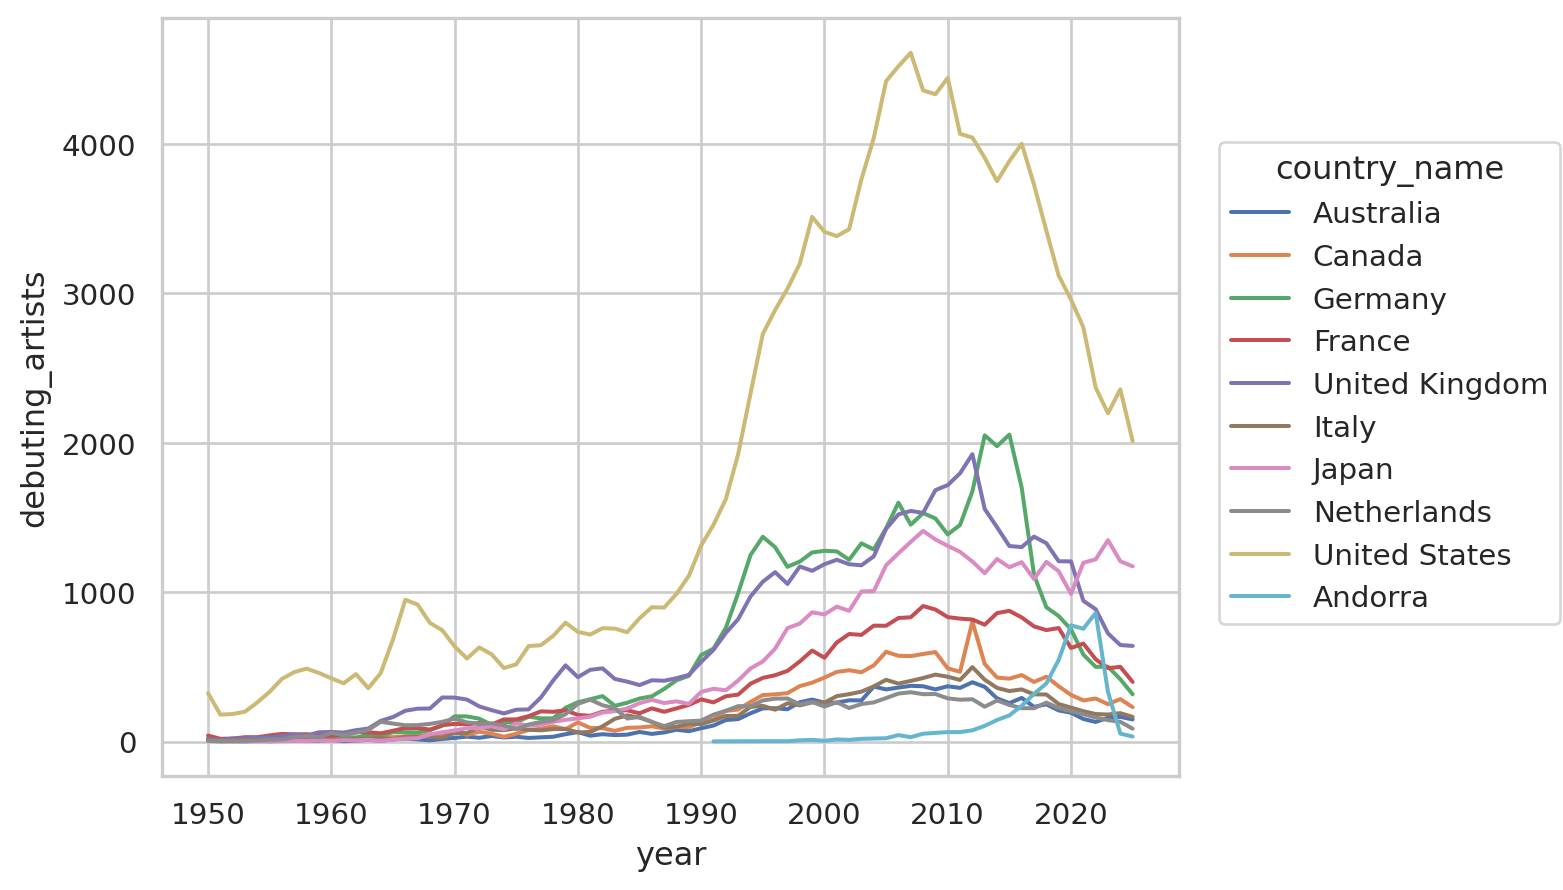

In [10]:
# Calculating the average number of debut releases by country in order to use it to filter the top 10 countries per average number of releases
x = 132
country_average = (
    debut_count
      .groupby("country_name")["debuting_artists"]
      .mean()
)

valid_countries = country_average[country_average >= x].index

debut_count_plot = debut_count[
    debut_count["country_name"].isin(valid_countries)
].reset_index(drop=True)

so.Plot(debut_count_plot, x="year", y="debuting_artists", color="country_name").add(so.Line()).theme(axes_style("whitegrid"))
      


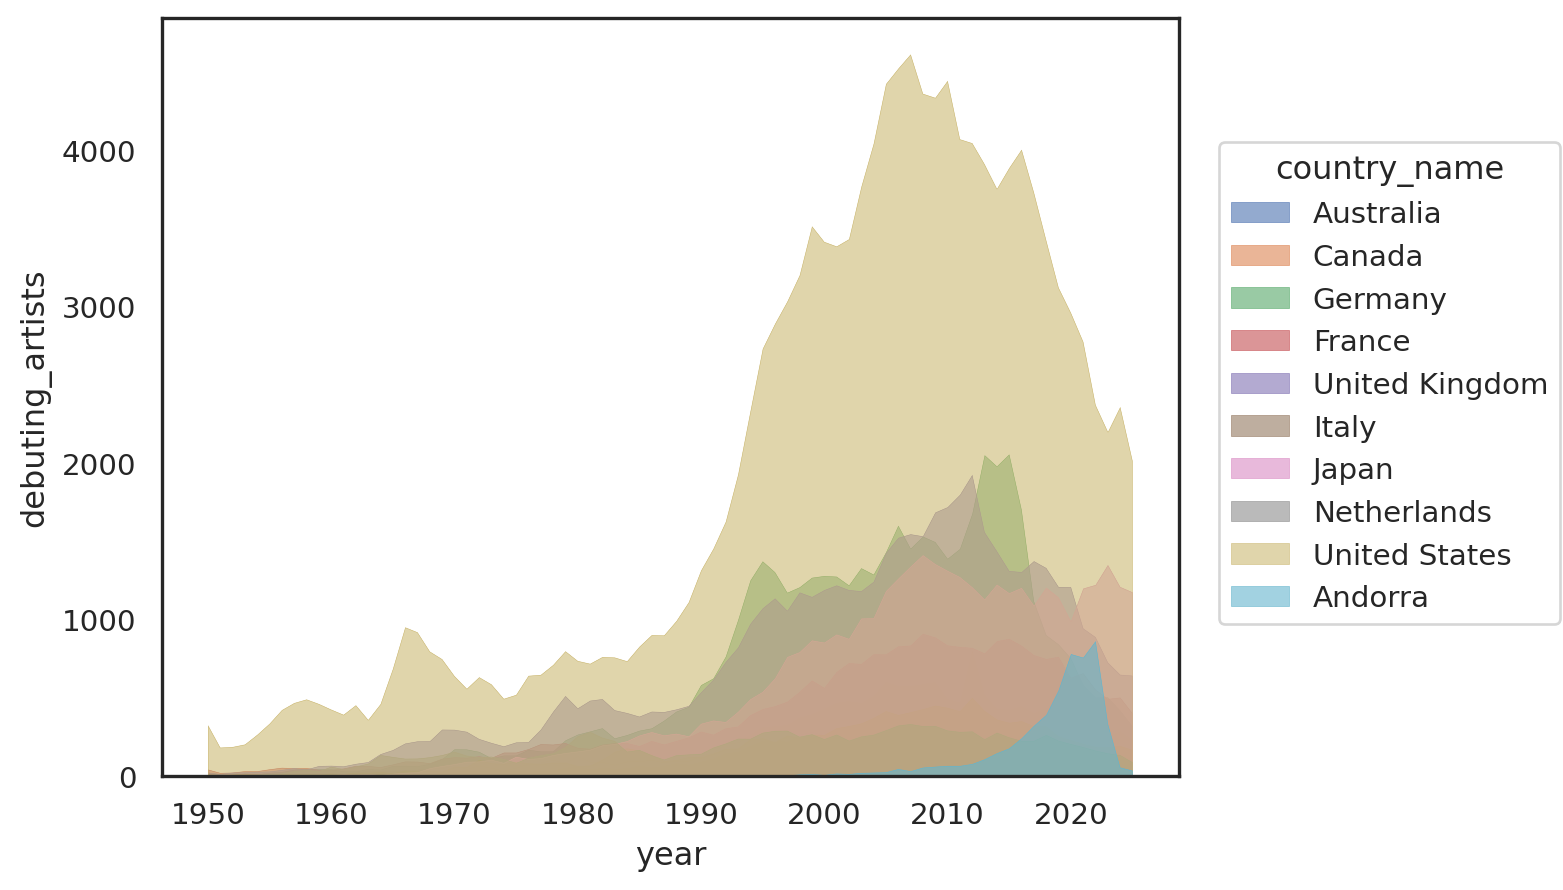

In [11]:
so.Plot(debut_count_plot, x="year", y="debuting_artists", color="country_name").add(so.Area(edgewidth=.2, alpha=.6)).theme(axes_style("white"))

**Plotting the last 20 years to measure the trends of the top 10 countries by average debut releases:**

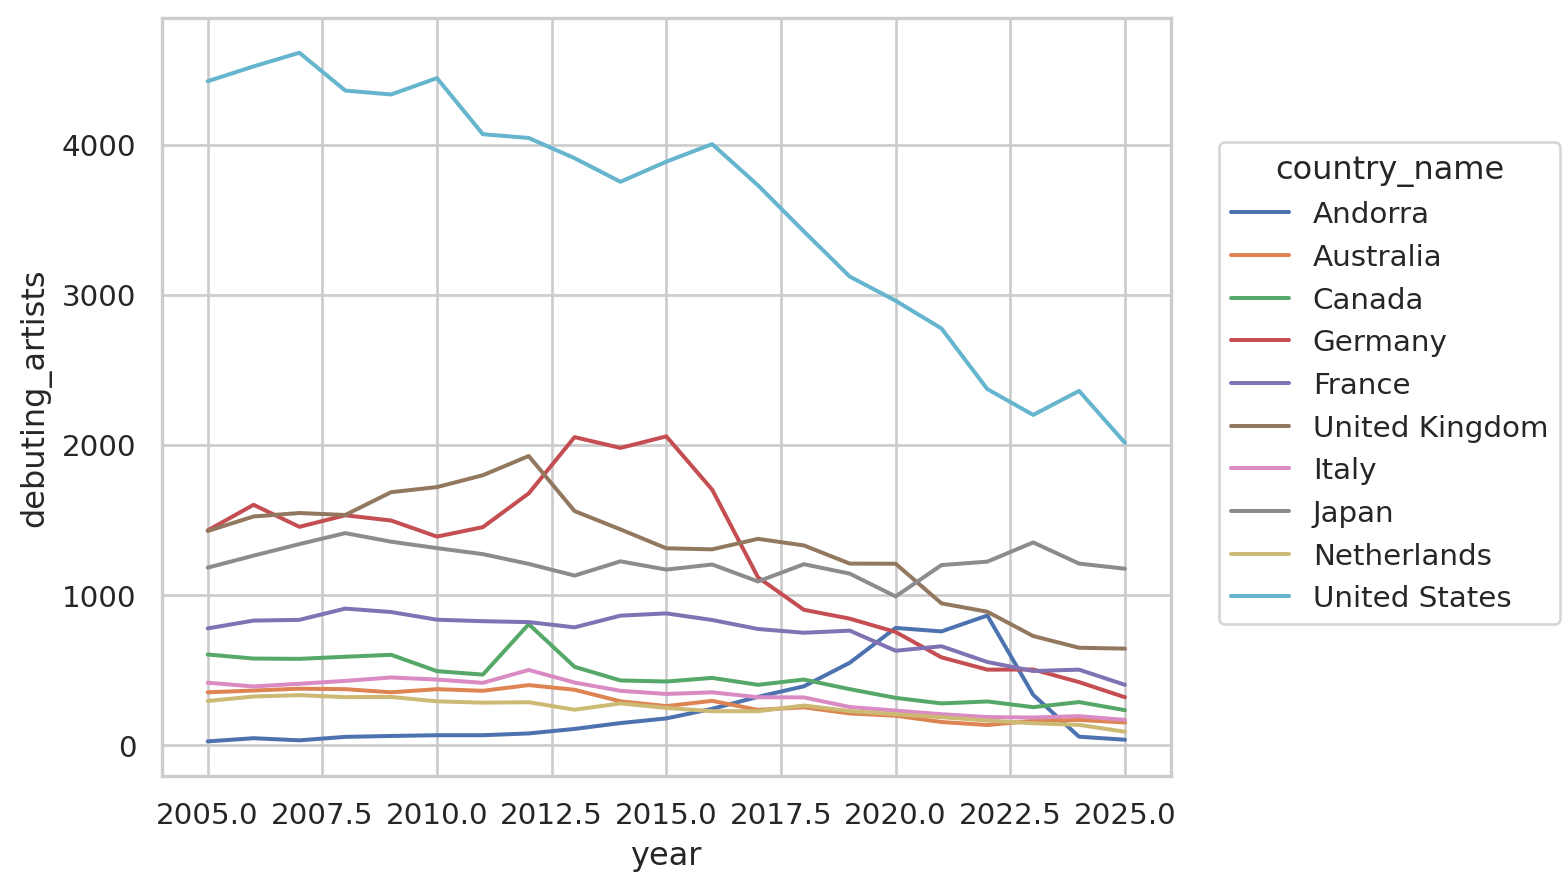

In [12]:
debut_count_plot2 = debut_count_plot[
    debut_count_plot["year"].between(2005, 2025)
].reset_index(drop=True)

so.Plot(debut_count_plot2, x="year", y="debuting_artists", color="country_name").add(so.Line()).theme(axes_style("whitegrid"))

In [13]:
# Calculating the % variation of the last 20 years
debuting_before = (
    debut_count_plot2.loc[debut_count_plot2["year"] == debut_count_plot2["year"].min()]
    .groupby("country_name")["debuting_artists"]
    .sum()
    .rename("debuting_before")
)

debuting_after = (
    debut_count_plot2.loc[debut_count_plot2["year"] == debut_count_plot2["year"].max()]
    .groupby("country_name")["debuting_artists"]
    .sum()
    .rename("debuting_after")
)

comparison = pd.concat([debuting_before, debuting_after], axis=1).dropna()

comparison["pct_variation"] = (
    (comparison["debuting_after"] - comparison["debuting_before"])
    / comparison["debuting_before"] * 100
)

debut_count_var = (
    comparison[["pct_variation"]]
    .reset_index()
    .rename(columns={"country": "country", "pct_variation": "pct_variation"})
    .sort_values("pct_variation")
    .reset_index(drop=True)
)

debut_count_var

,country_name,pct_variation
0,Germany,-77.871148
1,Netherlands,-70.446735
2,Canada,-61.730449
3,Italy,-60.048426
4,Australia,-57.593123
5,United Kingdom,-55.056180
6,United States,-54.500226
7,France,-48.516129
8,Japan,-0.593220
9,Andorra,50.000000


**Japan and Andorra being the only 2 countries where the number of new artists remained stable**